# 🔐 Cipher Classifier — Модуль 1: Генерация датасета

В этом ноутбуке мы:
1. Реализуем 6 классических шифров + класс plaintext
2. Зашифруем тексты каждым шифром
3. Сохраним датасет для обучения модели

**Шифры:** Цезарь, Виженер, Rail Fence, Атбаш, Плейфер, Бэкон

## 📦 Импорты

In [12]:
import random
import string
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print('✅ Все библиотеки загружены')

✅ Все библиотеки загружены


## 📝 Исходные тексты

In [13]:
RAW_TEXTS = [
    "The quick brown fox jumps over the lazy dog",
    "Mathematics is the language in which God has written the universe",
    "Cryptography is the practice and study of techniques for secure communication",
    "In the beginning God created the heavens and the earth",
    "To be or not to be that is the question whether tis nobler in the mind to suffer",
    "All human beings are born free and equal in dignity and rights",
    "It was the best of times it was the worst of times it was the age of wisdom",
    "Ask not what your country can do for you ask what you can do for your country",
    "The only way to do great work is to love what you do and believe in yourself",
    "In mathematics you do not understand things you just get used to them over time",
    "Science is organized knowledge wisdom is organized life and both require discipline",
    "The greatest enemy of knowledge is not ignorance it is the illusion of knowledge",
    "Logic will get you from point A to point B imagination will take you everywhere",
    "Pure mathematics is in its way the poetry of logical ideas and abstract thinking",
    "A mathematician is a device for turning coffee into theorems and proofs into results",
    "The universe is under no obligation to make sense to you but mathematics always does",
    "Without mathematics there is nothing you can do everything around you is mathematics",
    "Algebra is the offer made by the devil to the mathematician the devil says I will give",
    "There is no branch of mathematics however abstract which may not someday be applied",
    "Mathematics is not about numbers equations computations or algorithms it is about understanding",
]

def preprocess(text: str) -> str:
    """Приводим текст к верхнему регистру, оставляем только буквы"""
    return ''.join(c.upper() for c in text if c.isalpha())

TEXTS = [preprocess(t) for t in RAW_TEXTS]

print(f'Всего текстов: {len(TEXTS)}')
print(f'Пример: "{TEXTS[0][:40]}..."')
print(f'Средняя длина: {int(np.mean([len(t) for t in TEXTS]))} символов')

Всего текстов: 20
Пример: "THEQUICKBROWNFOXJUMPSOVERTHELAZYDOG..."
Средняя длина: 63 символов


## 🔑 Шифр 1: Цезарь

Сдвигает каждую букву на $k$ позиций: $E(x) = (x + k) \mod 26$

In [14]:
def caesar_encrypt(text: str, shift: int = None) -> str:
    if shift is None:
        shift = random.randint(1, 25)
    return ''.join(
        chr((ord(c) - ord('A') + shift) % 26 + ord('A')) if c.isalpha() else c
        for c in text
    )

print(f'Оригинал:  {TEXTS[0][:30]}')
print(f'Цезарь(3): {caesar_encrypt(TEXTS[0], 3)[:30]}')

Оригинал:  THEQUICKBROWNFOXJUMPSOVERTHELA
Цезарь(3): WKHTXLFNEURZQIRAMXPSVRYHUWKHOD


## 🔑 Шифр 2: Виженер

Многоалфавитный шифр: $E(x_i) = (x_i + k_{i \mod m}) \mod 26$

In [15]:
VIGENERE_KEYS = ['SECRET', 'CRYPTO', 'MATH', 'CIPHER', 'PYTHON', 'ALPHA', 'DELTA', 'OMEGA', 'KEY', 'LOCK']

def vigenere_encrypt(text: str, key: str = None) -> str:
    if key is None:
        key = random.choice(VIGENERE_KEYS)
    key = key.upper()
    result, key_idx = '', 0
    for char in text:
        if char.isalpha():
            shift = ord(key[key_idx % len(key)]) - ord('A')
            result += chr((ord(char) - ord('A') + shift) % 26 + ord('A'))
            key_idx += 1
        else:
            result += char
    return result

print(f'Оригинал:     {TEXTS[0][:30]}')
print(f'Виженер(KEY): {vigenere_encrypt(TEXTS[0], "KEY")[:30]}')

Оригинал:     THEQUICKBROWNFOXJUMPSOVERTHELA
Виженер(KEY): DLCAYGMOZBSUXJMHNSWTQYZCBXFOPY


## 🔑 Шифр 3: Rail Fence

Буквы записываются зигзагом по $r$ рельсам, затем читаются построчно.

In [16]:
def rail_fence_encrypt(text: str, rails: int = None) -> str:
    if rails is None:
        rails = random.randint(2, 4)
    fence = [[] for _ in range(rails)]
    rail, direction = 0, 1
    for char in text:
        fence[rail].append(char)
        if rail == 0: direction = 1
        elif rail == rails - 1: direction = -1
        rail += direction
    return ''.join(''.join(r) for r in fence)

print(f'Оригинал:      {TEXTS[0][:30]}')
print(f'Rail Fence(3): {rail_fence_encrypt(TEXTS[0], 3)[:30]}')

Оригинал:      THEQUICKBROWNFOXJUMPSOVERTHELA
Rail Fence(3): TUBNJSRLDHQIKRWFXUPOETEAYOECOO


## 🔑 Шифр 4: Атбаш

Зеркальная замена: $E(x) = 25 - x$, то есть A↔Z, B↔Y, ...

In [17]:
def atbash_encrypt(text: str) -> str:
    return ''.join(
        chr(ord('Z') - (ord(c.upper()) - ord('A'))) if c.isalpha() else c
        for c in text
    )

print(f'Оригинал: {TEXTS[0][:30]}')
print(f'Атбаш:    {atbash_encrypt(TEXTS[0])[:30]}')

Оригинал: THEQUICKBROWNFOXJUMPSOVERTHELA
Атбаш:    GSVJFRXPYILDMULCQFNKHLEVIGSVOZ


## 🔑 Шифр 5: Плейфер

Шифрует **пары букв (диграммы)** с помощью матрицы 5×5, составленной из ключевого слова.

Алгоритм:
1. Строим матрицу 5×5 из ключевого слова (I и J объединяются в одну клетку)
2. Разбиваем текст на пары — если буквы одинаковые, вставляем X между ними
3. Для каждой пары применяем одно из трёх правил:
   - **Одна строка** → сдвиг вправо
   - **Один столбец** → сдвиг вниз  
   - **Прямоугольник** → меняем столбцы местами

In [18]:
PLAYFAIR_KEYS = ['MONARCHY', 'KEYWORD', 'PLAYFAIR', 'SECURITY', 'MATRIX', 'CRYPTO', 'CIPHER']

def build_playfair_matrix(key: str):
    """Строим матрицу 5×5 из ключевого слова. I и J — одна клетка."""
    key = key.upper().replace('J', 'I')
    seen = set()
    matrix_chars = []
    for c in key + string.ascii_uppercase:
        if c == 'J': continue
        if c not in seen:
            seen.add(c)
            matrix_chars.append(c)
    return [matrix_chars[i*5:(i+1)*5] for i in range(5)]

def playfair_position(matrix, char):
    """Находим позицию буквы в матрице"""
    for r, row in enumerate(matrix):
        for c, cell in enumerate(row):
            if cell == char:
                return r, c
    return None

def playfair_encrypt(text: str, key: str = None) -> str:
    if key is None:
        key = random.choice(PLAYFAIR_KEYS)
    
    matrix = build_playfair_matrix(key)
    
    # Подготовка текста: заменяем J→I, разбиваем на диграммы
    text = text.upper().replace('J', 'I')
    text = ''.join(c for c in text if c.isalpha())
    
    # Формируем пары, вставляя X между одинаковыми буквами
    pairs = []
    i = 0
    while i < len(text):
        a = text[i]
        if i + 1 >= len(text):
            b = 'X'
        elif text[i] == text[i + 1]:
            b = 'X'
            i -= 1  # не продвигаемся по второй букве
        else:
            b = text[i + 1]
        pairs.append((a, b))
        i += 2
    
    result = ''
    for a, b in pairs:
        ra, ca = playfair_position(matrix, a)
        rb, cb = playfair_position(matrix, b)
        
        if ra == rb:  # одна строка — сдвиг вправо
            result += matrix[ra][(ca + 1) % 5]
            result += matrix[rb][(cb + 1) % 5]
        elif ca == cb:  # один столбец — сдвиг вниз
            result += matrix[(ra + 1) % 5][ca]
            result += matrix[(rb + 1) % 5][cb]
        else:  # прямоугольник — меняем столбцы
            result += matrix[ra][cb]
            result += matrix[rb][ca]
    
    return result

print(f'Оригинал:  {TEXTS[0][:30]}')
print(f'Плейфер:   {playfair_encrypt(TEXTS[0], "MONARCHY")[:30]}')
print()
print('Матрица для ключа MONARCHY:')
matrix = build_playfair_matrix('MONARCHY')
for row in matrix:
    print(' '.join(row))

Оригинал:  THEQUICKBROWNFOXJUMPSOVERTHELA
Плейфер:   PDGLXEDEDANVOGAVEXOLPAUFDZCFSM

Матрица для ключа MONARCHY:
M O N A R
C H Y B D
E F G I K
L P Q S T
U V W X Z


## 🔑 Шифр 6: Бэкон

Каждая буква кодируется 5-битной последовательностью из символов A и B:

$$A = AAAAA, \quad B = AAAAB, \quad C = AAABA, \quad \ldots, \quad Z = BBBBB$$

Это по сути бинарное кодирование: A=0, B=1, и $E(x) = \text{bin}(x)$ в 5 битах.

Особенность: зашифрованный текст **в 5 раз длиннее** оригинала и содержит **только буквы A и B**.

In [19]:
def bacon_encrypt(text: str) -> str:
    """Шифр Бэкона: каждая буква → 5 символов (A или B)"""
    result = ''
    for char in text:
        if char.isalpha():
            # Порядковый номер буквы (0-25), кодируем в 5 бит
            n = ord(char.upper()) - ord('A')
            # Каждый бит: 0 → A, 1 → B
            result += ''.join('B' if (n >> (4 - i)) & 1 else 'A' for i in range(5))
    return result

demo = 'HELLO'
encrypted = bacon_encrypt(demo)
print(f'Оригинал: {demo}')
print(f'Бэкон:    {encrypted}')
print(f'Длина: {len(demo)} → {len(encrypted)} символов (×{len(encrypted)//len(demo)})')
print()
print(f'Уникальные буквы в зашифрованном тексте: {set(encrypted)}')
print()
# Для датасета берём только начало, чтобы длина была сопоставима с другими
sample_bacon = bacon_encrypt(TEXTS[0][:20])
print(f'Пример (первые 20 букв текста → Бэкон): {sample_bacon[:40]}...')

Оригинал: HELLO
Бэкон:    AABBBAABAAABABBABABBABBBA
Длина: 5 → 25 символов (×5)

Уникальные буквы в зашифрованном тексте: {'B', 'A'}

Пример (первые 20 букв текста → Бэкон): BAABBAABBBAABAABAAAABABAAABAAAAAABAABABA...


## 📊 Генерация датасета

7 классов × 300 примеров = **2100 строк итого**.

⚠️ Для шифра Бэкона берём короткие фрагменты текста (20 букв → 100 символов), иначе тексты будут слишком длинными по сравнению с остальными.

In [20]:
SAMPLES_PER_CIPHER = 300

def get_random_fragment(text: str, min_len: int = 30) -> str:
    """Возвращает случайный фрагмент текста длиной не менее min_len"""
    if len(text) <= min_len:
        return text
    start = random.randint(0, len(text) - min_len)
    return text[start:start + random.randint(min_len, len(text) - start)]

CIPHERS = {
    'plaintext':  lambda t: t,
    'caesar':     caesar_encrypt,
    'vigenere':   vigenere_encrypt,
    'rail_fence': rail_fence_encrypt,
    'atbash':     atbash_encrypt,
    'playfair':   playfair_encrypt,
    'bacon':      lambda t: bacon_encrypt(t[:20]),  # короткий фрагмент
}

records = []

for label, encrypt_fn in CIPHERS.items():
    for _ in range(SAMPLES_PER_CIPHER):
        text = get_random_fragment(random.choice(TEXTS))
        encrypted = encrypt_fn(text)
        records.append({'ciphertext': encrypted, 'label': label})

df = pd.DataFrame(records).sample(frac=1, random_state=42).reset_index(drop=True)

print(f'Размер датасета: {len(df)} строк')
print(f'\nРаспределение по классам:')
print(df['label'].value_counts())
print(f'\nПример строки (Плейфер):')
print(df[df['label'] == 'playfair'].iloc[0]['ciphertext'][:60], '...')

Размер датасета: 2100 строк

Распределение по классам:
label
rail_fence    300
plaintext     300
atbash        300
vigenere      300
bacon         300
caesar        300
playfair      300
Name: count, dtype: int64

Пример строки (Плейфер):
SFQDMTYOKIMAKUSVSASCLDEUBLQDMC ...


## 📈 Визуализация: частотный анализ для всех 7 классов

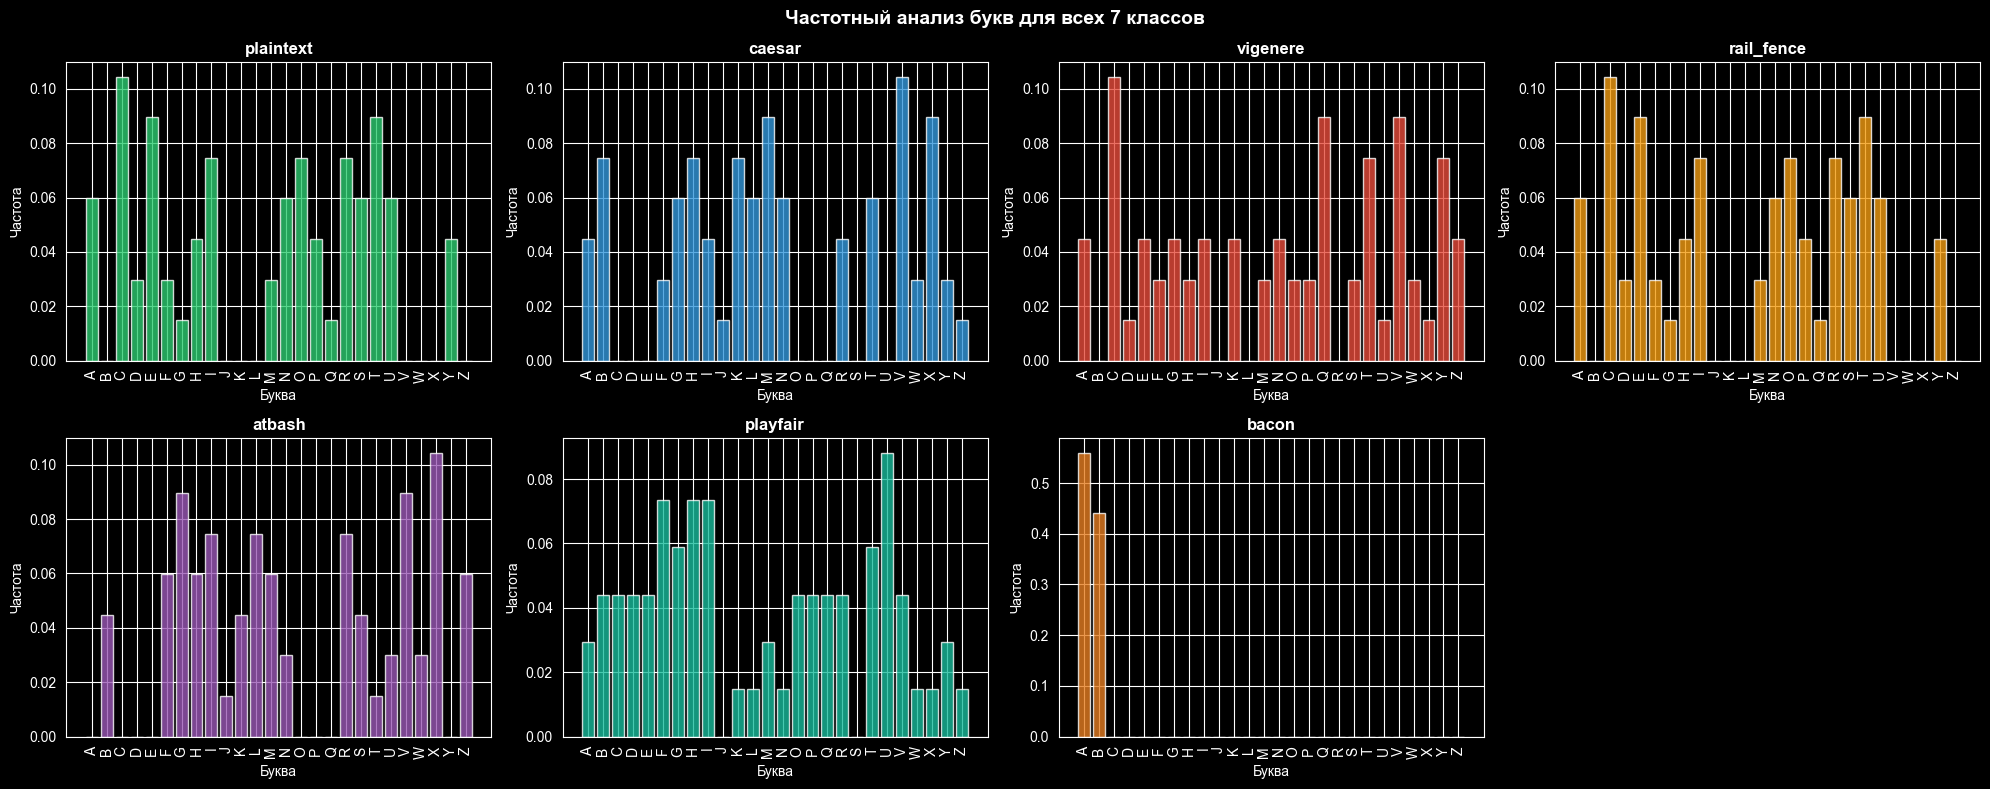

💡 Обрати внимание:
   Бэкон: только буквы A и B — самый лёгкий для распознавания
   Виженер: самое равномерное распределение — самый сложный
   Цезарь vs Plaintext: одинаковая форма, просто сдвинутая


In [21]:
def letter_freq(text: str) -> list:
    """Относительная частота каждой буквы (список из 26 значений)"""
    text = ''.join(c for c in text.upper() if c.isalpha())
    total = len(text)
    if total == 0:
        return [0.0] * 26
    return [text.count(chr(ord('A') + i)) / total for i in range(26)]

# Берём один текст, шифруем всеми шифрами
demo_text = TEXTS[2]
labels = list(CIPHERS.keys())
colors = ['#2ecc71', '#3498db', '#e74c3c', '#f39c12', '#9b59b6', '#1abc9c', '#e67e22']

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes = axes.flatten()
fig.suptitle('Частотный анализ букв для всех 7 классов', fontsize=14, fontweight='bold')

letters = list(string.ascii_uppercase)

for i, (label, encrypt_fn) in enumerate(CIPHERS.items()):
    text = demo_text[:20] if label == 'bacon' else demo_text
    ctext = encrypt_fn(text)
    freq = letter_freq(ctext)
    axes[i].bar(letters, freq, color=colors[i], alpha=0.8)
    axes[i].set_title(label, fontweight='bold', fontsize=12)
    axes[i].set_xlabel('Буква')
    axes[i].set_ylabel('Частота')
    axes[i].tick_params(axis='x', rotation=90)

axes[-1].set_visible(False)  # скрываем пустой 8-й график
plt.tight_layout()
plt.savefig('frequency_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print('💡 Обрати внимание:')
print('   Бэкон: только буквы A и B — самый лёгкий для распознавания')
print('   Виженер: самое равномерное распределение — самый сложный')
print('   Цезарь vs Plaintext: одинаковая форма, просто сдвинутая')

## 💾 Сохранение датасета

In [22]:
df.to_csv('cipher_dataset.csv', index=False)
print(f'✅ Датасет сохранён: cipher_dataset.csv')
print(f'   Строк: {len(df)}')
print(f'   Классов: {df["label"].nunique()}')
print(f'   Колонки: {list(df.columns)}')
print()
df.head(10)

✅ Датасет сохранён: cipher_dataset.csv
   Строк: 2100
   Классов: 7
   Колонки: ['ciphertext', 'label']



,ciphertext,label
0,GLUOOBNWKILGOFPITPTIIANIAECIEYRMNAONMGTOLTYWTO...,rail_fence
1,TERCIENSUYFEHIUSOSCHPATCADTDOTCNQEFRE,rail_fence
2,ATHEMATICSISNOTABOUTNUMBERSEQUATIONSCOMPUTATIO...,plaintext
3,SZGRHGSVJFVHGRLMDSVGSVIGRHMLYOVIRMGSVNRMW,atbash
4,IXMSVFGRRTWHJVFTTJGEQPGRVYCTTFVY,vigenere
5,ABBBABABAABAABBABBAAAAAAABAABBAABBBAABAAABBAAA...,bacon
6,EOSOHOAEVYSAWRITLVWAYUONBLEENORETKOETDDIIUL,rail_fence
7,KVQOLBKSCDROYPPOBWKNOLIDRONOFSVDYDROW,caesar
8,XRZMRHZWVERXVULIGFIMRMTXLUUVVRMGLGS,atbash
9,SFQDMTYOKIMAKUSVSASCLDEUBLQDMC,playfair


## ✅ Итог модуля 1

Создан датасет из **2100 примеров** (7 классов × 300):

| Класс | Ключевой признак |
|---|---|
| plaintext | Типичное английское распределение |
| caesar | То же распределение, сдвинутое |
| vigenere | Более равномерное распределение |
| rail_fence | Распределение как у plaintext, но структура другая |
| atbash | Зеркальное распределение |
| playfair | Уникальные диграммы, нет удвоенных букв |
| bacon | Только буквы A и B |

**Следующий шаг — Модуль 2:** извлечение признаков и обучение Random Forest классификатора.